In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chart display and styling
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset
df = pd.read_csv("retail_sales_dataset.csv")

# Display the first five records
display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
# Number of rows and columns
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Unique values in categorical columns
print("\nCategorical column summaries:")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts().head(10))

Dataset shape: (1000, 9)
Number of rows: 1000
Number of columns: 9

Column names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 100.2 KB

Missing values in each column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age           

C:\Users\gopik\AppData\Local\Temp\ipykernel_2360\3052606053.py:23: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [3]:
# Standardize column names for consistent access
df.columns = (
    df.columns.str.strip()
    .str.replace(r"([a-z])([A-Z])", r"\1_\2", regex=True)
    .str.replace(r"[\s\-]+", "_", regex=True)
    .str.lower()
)

print("Cleaned column names:")
print(df.columns.tolist())

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert numeric columns
numeric_candidates = [
    "age", "quantity", "price_per_unit", "total_amount"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove fully duplicated rows
df = df.drop_duplicates().copy()

# Remove records without valid dates
df = df.dropna(subset=["date"]).copy()

# Inspect remaining missing values
print("\nMissing values after basic cleaning:")
print(df.isnull().sum())

display(df.head())

Cleaned column names:
['transaction_id', 'date', 'customer_id', 'gender', 'age', 'product_category', 'quantity', 'price_per_unit', 'total_amount']

Missing values after basic cleaning:
transaction_id      0
date                0
customer_id         0
gender              0
age                 0
product_category    0
quantity            0
price_per_unit      0
total_amount        0
dtype: int64


,transaction_id,date,customer_id,gender,age,product_category,quantity,price_per_unit,total_amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Mean, median, mode, and standard deviation
summary = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Standard Deviation": numeric_df.std(),
    "Minimum": numeric_df.min(),
    "Maximum": numeric_df.max()
})

display(summary.round(2))

,Mean,Median,Mode,Standard Deviation,Minimum,Maximum
transaction_id,500.50,500.5,1.0,288.82,1,1000
age,41.39,42.0,43.0,13.68,18,64
quantity,2.51,3.0,4.0,1.13,1,4
price_per_unit,179.89,50.0,50.0,189.68,25,500
total_amount,456.00,135.0,50.0,560.00,25,2000


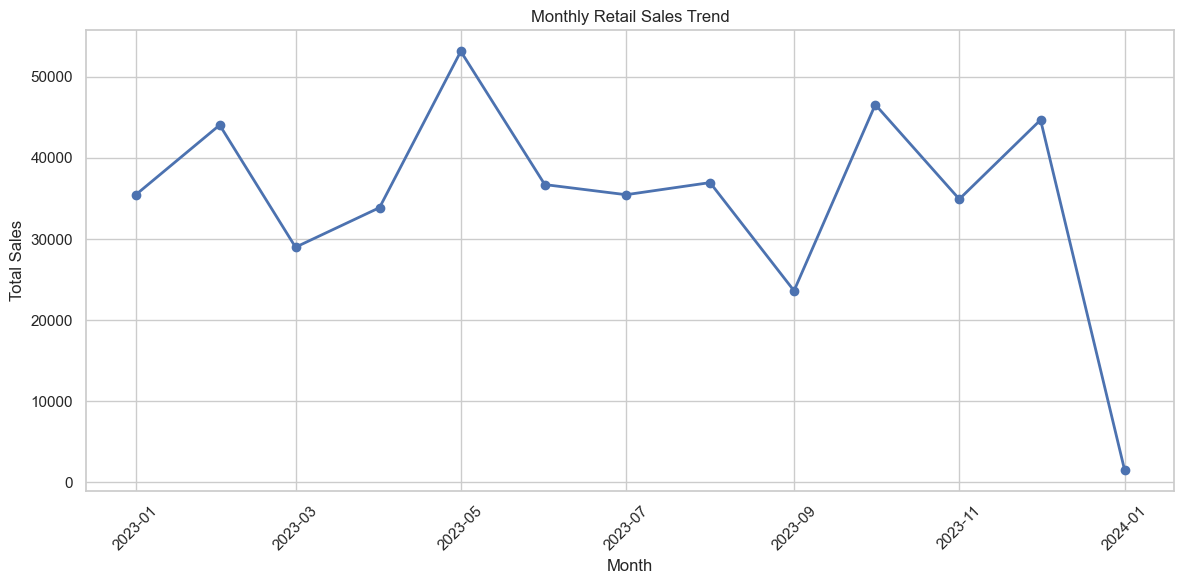

Highest-sales month: May 2023
Highest monthly sales: 53150
Lowest-sales month: January 2024
Lowest monthly sales: 1530


In [5]:
# Group sales by month
monthly_sales = (
    df.set_index("date")["total_amount"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Identify strongest and weakest months
if not monthly_sales.empty:
    print("Highest-sales month:", monthly_sales.idxmax().strftime("%B %Y"))
    print("Highest monthly sales:", round(monthly_sales.max(), 2))
    print("Lowest-sales month:", monthly_sales.idxmin().strftime("%B %Y"))
    print("Lowest monthly sales:", round(monthly_sales.min(), 2))

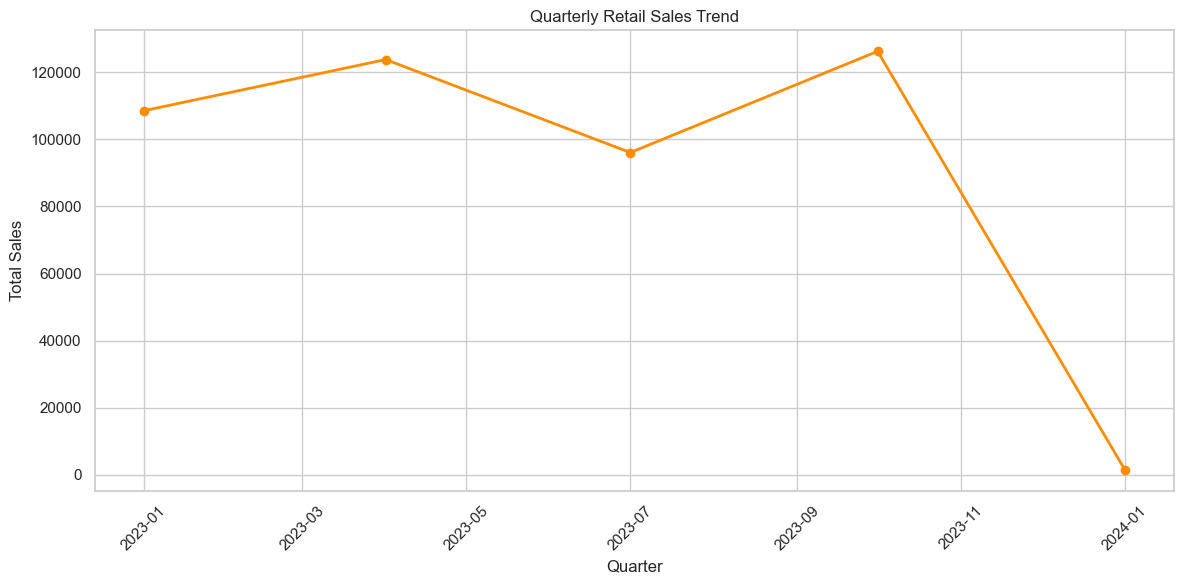

Quarterly sales summary:


,Total Sales
date,
2023-01-01,108500
2023-04-01,123735
2023-07-01,96045
2023-10-01,126190
2024-01-01,1530


In [6]:
quarterly_sales = (
    df.set_index("date")["total_amount"]
    .resample("QS")
    .sum()
)

plt.figure(figsize=(12, 6))
plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker="o",
    color="darkorange",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Quarterly sales summary:")
display(quarterly_sales.to_frame(name="Total Sales").round(2))

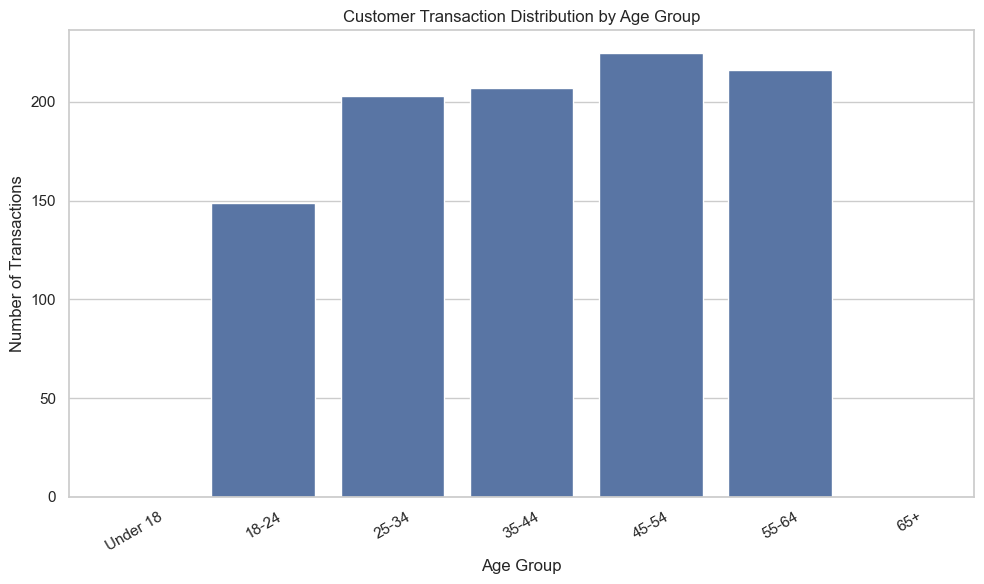

Transactions by age group:


,Transactions
age_group,
Under 18,0
18-24,149
25-34,203
35-44,207
45-54,225
55-64,216
65+,0


In [7]:
age_bins = [0, 18, 25, 35, 45, 55, 65, 120]
age_labels = [
    "Under 18", "18-24", "25-34", "35-44",
    "45-54", "55-64", "65+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_counts = df["age_group"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
sns.barplot(
    x=age_counts.index.astype(str),
    y=age_counts.values
)

plt.title("Customer Transaction Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Transactions by age group:")
display(age_counts.to_frame(name="Transactions"))

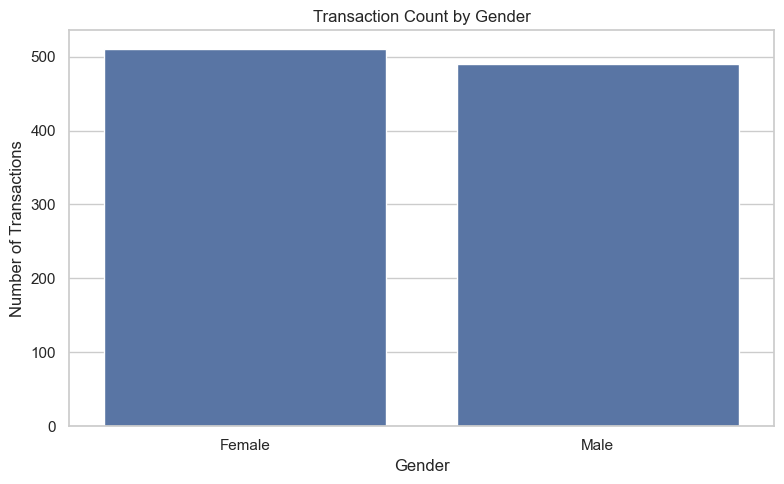

,Transactions,Total_Sales,Average_Transaction
gender,,,
Female,510,232840,456.55
Male,490,223160,455.43


In [8]:
gender_counts = df["gender"].value_counts(dropna=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=gender_counts.index.astype(str),
    y=gender_counts.values
)

plt.title("Transaction Count by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

# Compare both transaction counts and sales
gender_sales = df.groupby("gender", dropna=False).agg(
    Transactions=("total_amount", "size"),
    Total_Sales=("total_amount", "sum"),
    Average_Transaction=("total_amount", "mean")
).sort_values("Total_Sales", ascending=False)

display(gender_sales.round(2))

,Units_Sold,Total_Revenue
product_category,,
Clothing,894,155580
Electronics,849,156905
Beauty,771,143515


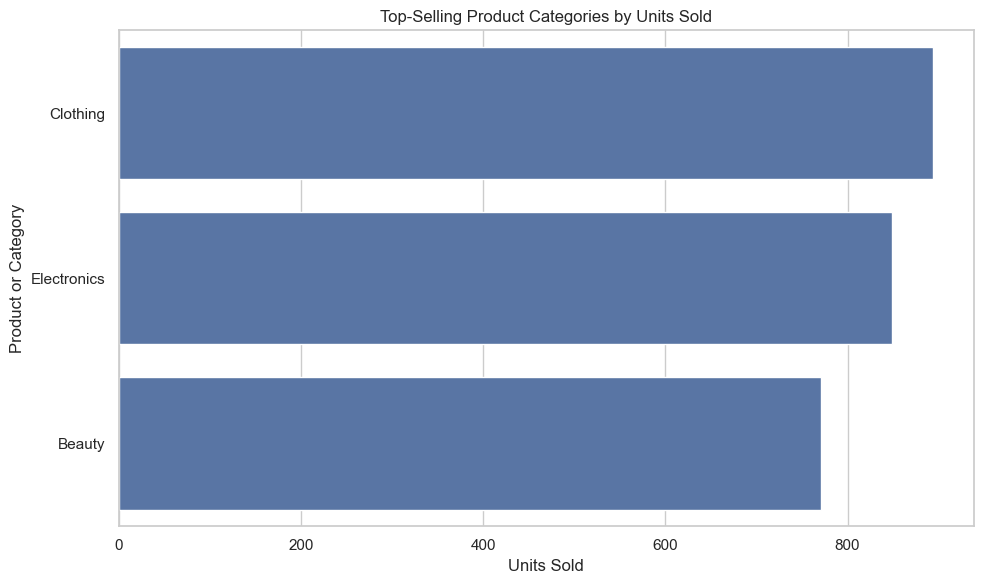

In [9]:
# Detect available product-level columns
possible_product_cols = [
    "product_name", "product", "product_id",
    "item_name", "item", "sku"
]

product_col = next(
    (col for col in possible_product_cols if col in df.columns),
    None
)

if product_col:
    top_products = (
        df.groupby(product_col)
        .agg(
            Units_Sold=("quantity", "sum"),
            Total_Revenue=("total_amount", "sum")
        )
        .sort_values("Units_Sold", ascending=False)
        .head(10)
    )

    chart_title = "Top 10 Best-Selling Products by Units Sold"
    x_label = "Units Sold"

else:
    top_products = (
        df.groupby("product_category")
        .agg(
            Units_Sold=("quantity", "sum"),
            Total_Revenue=("total_amount", "sum")
        )
        .sort_values("Units_Sold", ascending=False)
        .head(10)
    )

    chart_title = "Top-Selling Product Categories by Units Sold"
    x_label = "Units Sold"

display(top_products.round(2))

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_products["Units_Sold"].values,
    y=top_products.index.astype(str)
)

plt.title(chart_title)
plt.xlabel(x_label)
plt.ylabel("Product or Category")
plt.tight_layout()
plt.show()

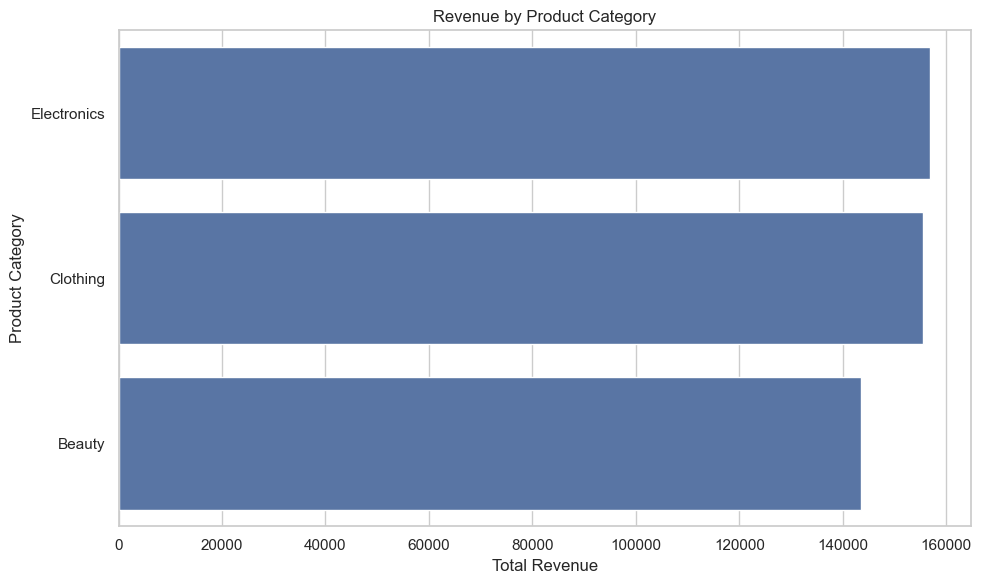

,Total Revenue
product_category,
Electronics,156905
Clothing,155580
Beauty,143515


Highest-revenue category: Electronics


In [10]:
category_revenue = (
    df.groupby("product_category")["total_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index.astype(str)
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

display(category_revenue.to_frame(name="Total Revenue").round(2))

print(
    "Highest-revenue category:",
    category_revenue.idxmax()
)

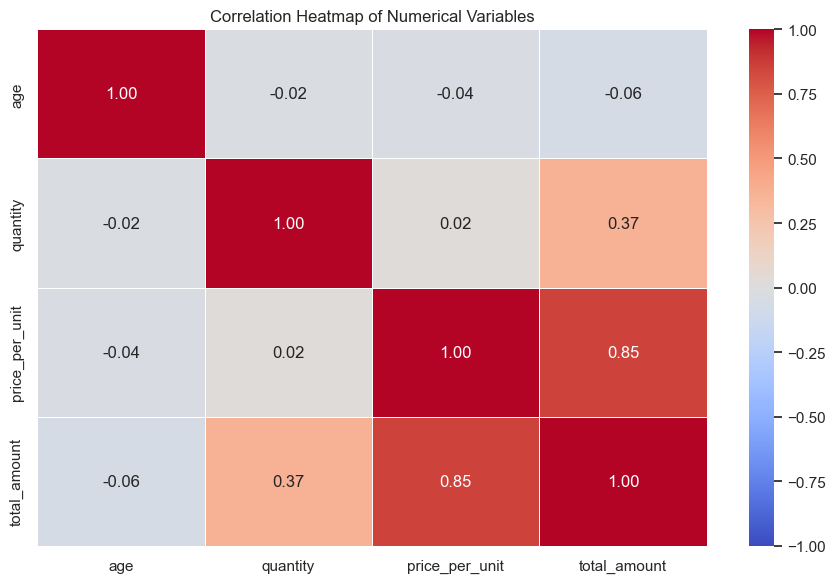

,age,quantity,price_per_unit,total_amount
age,1.00,-0.02,-0.04,-0.06
quantity,-0.02,1.00,0.02,0.37
price_per_unit,-0.04,0.02,1.00,0.85
total_amount,-0.06,0.37,0.85,1.00


In [11]:
# Select relevant numeric columns
correlation_cols = [
    col for col in [
        "age", "quantity", "price_per_unit", "total_amount"
    ]
    if col in df.columns
]

correlation_matrix = df[correlation_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))

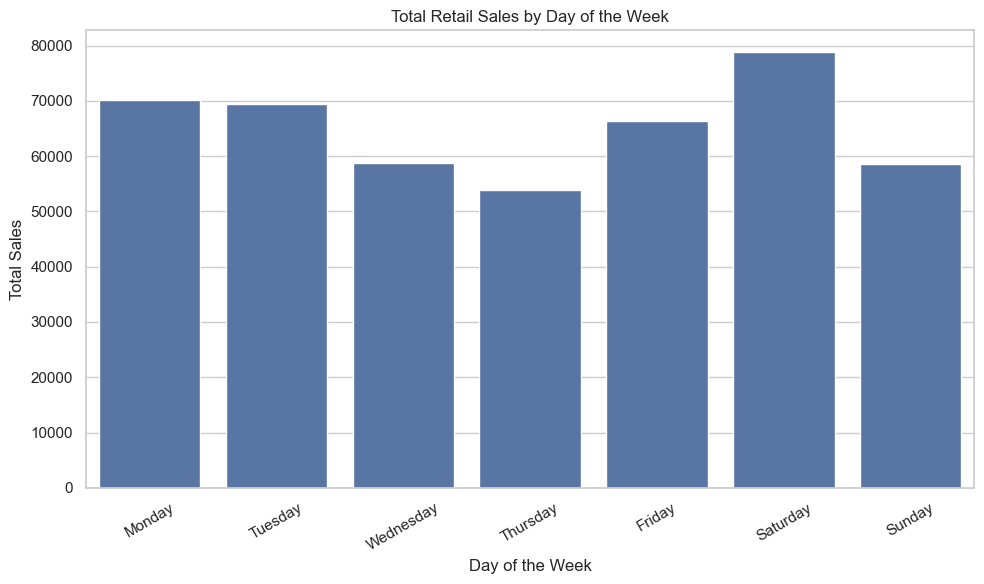

,Total Sales
day_of_week,
Monday,70250
Tuesday,69440
Wednesday,58770
Thursday,53835
Friday,66290
Saturday,78815
Sunday,58600


Highest-sales weekday: Saturday
Lowest-sales weekday: Thursday


In [12]:
# Extract day of week
df["day_of_week"] = df["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("day_of_week")["total_amount"]
    .sum()
    .reindex(weekday_order, fill_value=0)
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Total Retail Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(weekday_sales.to_frame(name="Total Sales").round(2))

print("Highest-sales weekday:", weekday_sales.idxmax())
print("Lowest-sales weekday:", weekday_sales.idxmin())

In [13]:
total_revenue = df["total_amount"].sum()
total_transactions = len(df)
unique_customers = df["customer_id"].nunique()
average_transaction_value = df["total_amount"].mean()
total_units_sold = df["quantity"].sum()

kpis = pd.Series({
    "Total Revenue": total_revenue,
    "Total Transactions": total_transactions,
    "Unique Customers": unique_customers,
    "Average Transaction Value": average_transaction_value,
    "Total Units Sold": total_units_sold
})

display(kpis.to_frame(name="Value").round(2))

,Value
Total Revenue,456000.0
Total Transactions,1000.0
Unique Customers,1000.0
Average Transaction Value,456.0
Total Units Sold,2514.0
